# MuSiQue · LLM baselines (local)

Seven LLMs answer directly from the same facts as NARS, at k = 0, 4, 8, 16 distractor paragraphs: gemma-3 4B/12B/27B,
Mistral-Small-24B, Llama-3.3-70B, Qwen3-Next-80B-A3B, DeepSeek-V3 (all on DeepInfra; the 8B reference runs in
`run_nars_lora.ipynb`). Scored by exact match and the Qwen3-235B judge.

Answers go to `results/answers/<model>/k<k>.jsonl` as they finish; running again only runs what is missing.
`N_QUESTIONS` runs the first N questions (try 10 first). Cost for 200 questions: about $3.

In [1]:
import sys
sys.path.insert(0, "../common")
import experiment as ex

DATASET = "MuSiQue"
N_QUESTIONS = 200             # the first N questions; 10 for a quick check
K_VALUES = ex.K_VALUES[DATASET]   # 0, 4, 8, 16
WORKERS = 16

questions, question_hash = ex.load_questions("questions.pkl", N_QUESTIONS)
client = ex.deepinfra()
ex.check_models([(client, model) for model in ex.BASELINES.values()] + [(client, ex.JUDGE_MODEL)])
systems = {name: (client, model, None) for name, model in ex.BASELINES.items()}
print(f"{len(questions)} questions · k = {K_VALUES} · {len(systems)} models")

8 models answer under their own names
200 questions · k = [0, 4, 8, 16] · 7 models


In [2]:
ex.run_all(questions, question_hash, "results", systems, K_VALUES, workers=WORKERS)

pass 1: 5600 answers to run (0 of 5600 already saved: 200 questions × 7 systems × k = 0, 4, 8, 16)
[  100/5600] $0.00 · 0 min · running accuracy: gemma-3-4b k=0: 68% of 100
[  200/5600] $0.01 · 0 min · running accuracy: gemma-3-4b k=0: 67% of 199 · gemma-3-4b k=4: 0% of 1
✔ gemma-3-4b           k=0  finished:  66.5% judged correct (133/200)   [214/5600 · $0.01 · 0 min]
[  300/5600] $0.01 · 0 min · running accuracy: gemma-3-4b k=4: 45% of 100
[  400/5600] $0.02 · 0 min · running accuracy: gemma-3-4b k=4: 45% of 199 · gemma-3-4b k=8: 100% of 1
✔ gemma-3-4b           k=4  finished:  45.0% judged correct (90/200)   [407/5600 · $0.02 · 0 min]
[  500/5600] $0.03 · 1 min · running accuracy: gemma-3-4b k=8: 43% of 100
[  600/5600] $0.04 · 1 min · running accuracy: gemma-3-4b k=8: 45% of 199 · gemma-3-4b k=16: 100% of 1
✔ gemma-3-4b           k=8  finished:  45.0% judged correct (90/200)   [605/5600 · $0.04 · 1 min]
[  700/5600] $0.06 · 1 min · running accuracy: gemma-3-4b k=16: 39% of 100
[  8

## Report

Everything saved in `results/` (also NARS rows, once their answers are copied in).

MUSIQUE · 200 questions · 7994 answers · k = 0, 4, 8, 16

ACCURACY (%) · judge
+--------------------+-------------------+------+------+------+------+--------+-----+
| System             |        Size       | k=0  | k=4  | k=8  | k=16 | Δ 0→16 |  n  |
+--------------------+-------------------+------+------+------+------+--------+-----+
| gemma-3-4b         |         4B        | 66.5 | 45.0 | 45.0 | 36.0 | -30.5  | 200 |
| gemma-3-12b        |        12B        | 77.0 | 65.5 | 62.0 | 53.0 | -24.0  | 200 |
| Mistral-Small-24B  |        24B        | 85.0 | 77.5 | 67.0 | 66.0 | -19.0  | 200 |
| gemma-3-27b        |        27B        | 80.5 | 67.5 | 61.5 | 56.5 | -24.0  | 200 |
| Llama-3.3-70B      |        70B        | 83.5 | 74.0 | 69.0 | 67.5 | -16.0  | 200 |
| Qwen3-Next-80B-A3B |  80B (3B active)  | 79.5 | 66.5 | 66.0 | 61.0 | -18.5  | 200 |
| DeepSeek-V3        | 671B (37B active) | 84.0 | 76.0 | 76.0 | 70.5 | -13.5  | 200 |
| Llama-3.1-8B       |         8B        | 65.5 | 59.0 | 52.5

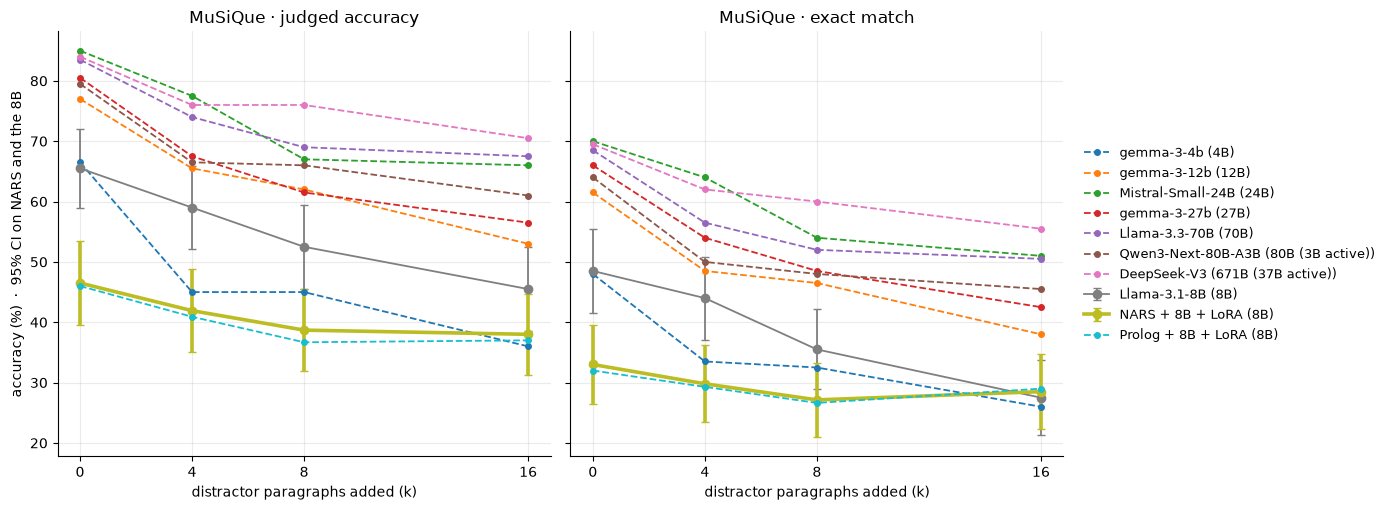

saved results/report.txt and results/accuracy_vs_k.png


In [3]:
ex.report("results", DATASET, N_QUESTIONS)